<xarray.Dataset> Size: 2GB
Dimensions:      (downtrack: 1280, crosstrack: 1242, bands: 285)
Dimensions without coordinates: downtrack, crosstrack, bands
Data variables:
    reflectance  (downtrack, crosstrack, bands) float32 2GB ...
Attributes: (12/37)
    ncei_template_version:             NCEI_NetCDF_Swath_Template_v2.0
    summary:                           The Earth Surface Mineral Dust Source ...
    keywords:                          Imaging Spectroscopy, minerals, EMIT, ...
    Conventions:                       CF-1.63
    sensor:                            EMIT (Earth Surface Mineral Dust Sourc...
    instrument:                        EMIT
    ...                                ...
    southernmost_latitude:             22.41394193571977
    spatialResolution:                 0.000542232520256367
    spatial_ref:                       GEOGCS["WGS 84",DATUM["WGS_1984",SPHER...
    geotransform:                      [ 5.73212924e+01  5.42232520e-04 -0.00...
    day_night_flag: 

Python(31978) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


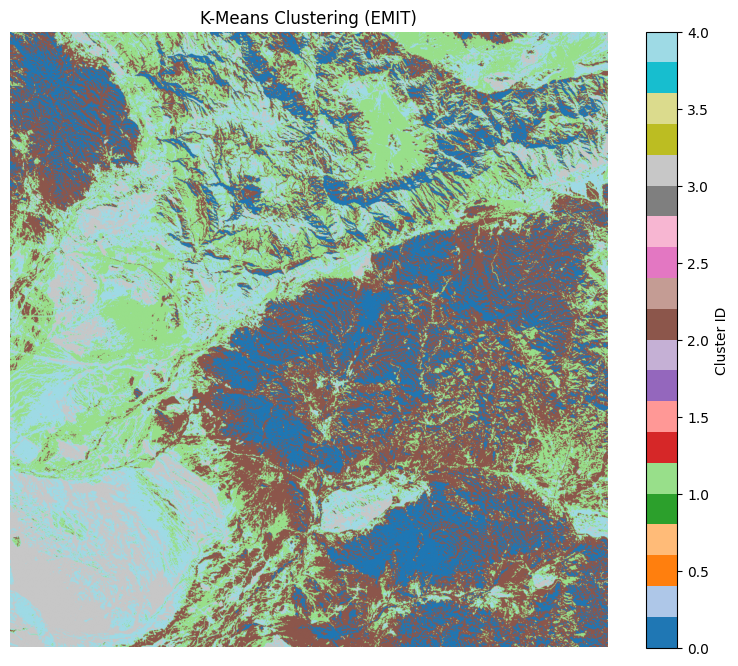

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# -----------------------------
# 1. Load EMIT NetCDF file
# -----------------------------
file_path = "EMIT_L2A_RFL_001_20260220T072251_2605105_013.nc"

ds = xr.open_dataset(file_path)

print(ds)  # Inspect variables

# -----------------------------
# 2. Extract reflectance cube
# -----------------------------
# Common EMIT variable name (may vary!)
# Try: reflectance, radiance, or rfl

if "reflectance" in ds:
    data = ds["reflectance"].values
elif "rfl" in ds:
    data = ds["rfl"].values
elif "radiance" in ds:
    data = ds["radiance"].values
else:
    raise ValueError("No valid spectral variable found!")

# Expected shape: (bands, rows, cols) OR (rows, cols, bands)
print("Original shape:", data.shape)

# -----------------------------
# 3. Fix dimension order
# -----------------------------
# Convert to (rows, cols, bands)
if data.shape[0] < 50:
    # Likely (bands, rows, cols)
    data = np.transpose(data, (1, 2, 0))

rows, cols, bands = data.shape
print("Reordered shape:", data.shape)

# -----------------------------
# 4. Reshape for ML
# -----------------------------
X = data.reshape(-1, bands)

# Remove invalid pixels
mask = np.all(np.isfinite(X), axis=1)
X_clean = X[mask]

print("Valid pixels:", X_clean.shape)

# -----------------------------
# 5. Normalize data
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# -----------------------------
# 6. Optional: PCA (VERY recommended)
# -----------------------------
pca = PCA(n_components=10)  # reduce dimensionality
X_pca = pca.fit_transform(X_scaled)

print("Explained variance:", np.sum(pca.explained_variance_ratio_))

# -----------------------------
# 7. Run K-Means
# -----------------------------
k = 5  # number of clusters

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)

# -----------------------------
# 8. Reconstruct image
# -----------------------------
full_labels = np.full(X.shape[0], -1)
full_labels[mask] = labels

cluster_map = full_labels.reshape(rows, cols)

# -----------------------------
# 9. Plot result
# -----------------------------
plt.figure(figsize=(10, 8))
plt.imshow(cluster_map, cmap="tab20")
plt.colorbar(label="Cluster ID")
plt.title("K-Means Clustering (EMIT)")
plt.axis("off")
plt.show()